# Mall Customer Segmentation Using K-Means Clustering

# A. Data Loading

In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [9]:
file_path = "Mall_Customers.csv"

if not os.path.exists(file_path):
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_files = [f for f in uploaded if f.lower().endswith(".csv")]
        if not csv_files:
            raise FileNotFoundError("Please upload a CSV file.")
        file_path = csv_files[0]
    except ImportError:
        raise FileNotFoundError("Put Mall_Customers.csv beside this notebook.")

df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()
df = df.rename(columns={"Genre": "Gender"})
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [10]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nFirst five rows:")
display(df.head())
print("\nLast five rows:")
display(df.tail())
print("\nBasic information:")
df.info()
print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Rows: 200
Columns: 5

Column names: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Data types:
 CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

First five rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Last five rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83



Basic information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0


# B. Data Preprocessing

In [11]:
print("Missing values by column:\n", df.isna().sum())
print("Exact duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()

# Domain checks: investigate any invalid records before removing or correcting them.
print("Invalid ages:", int((df["Age"] <= 0).sum()))
print("Non-positive incomes:", int((df["Annual Income (k$)"] <= 0).sum()))
print("Spending scores outside 1–100:",
      int((~df["Spending Score (1-100)"].between(1, 100)).sum()))

Missing values by column:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Exact duplicate rows: 0
Invalid ages: 0
Non-positive incomes: 0
Spending scores outside 1–100: 0


In [12]:
print("Numerical columns:", df.select_dtypes(include=np.number).columns.tolist())
print("Categorical columns:", df.select_dtypes(include="object").columns.tolist())

features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].copy()
display(X.head())

Numerical columns: ['CustomerID', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Categorical columns: ['Gender']


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


# C. Exploratory Data Analysis (EDA)

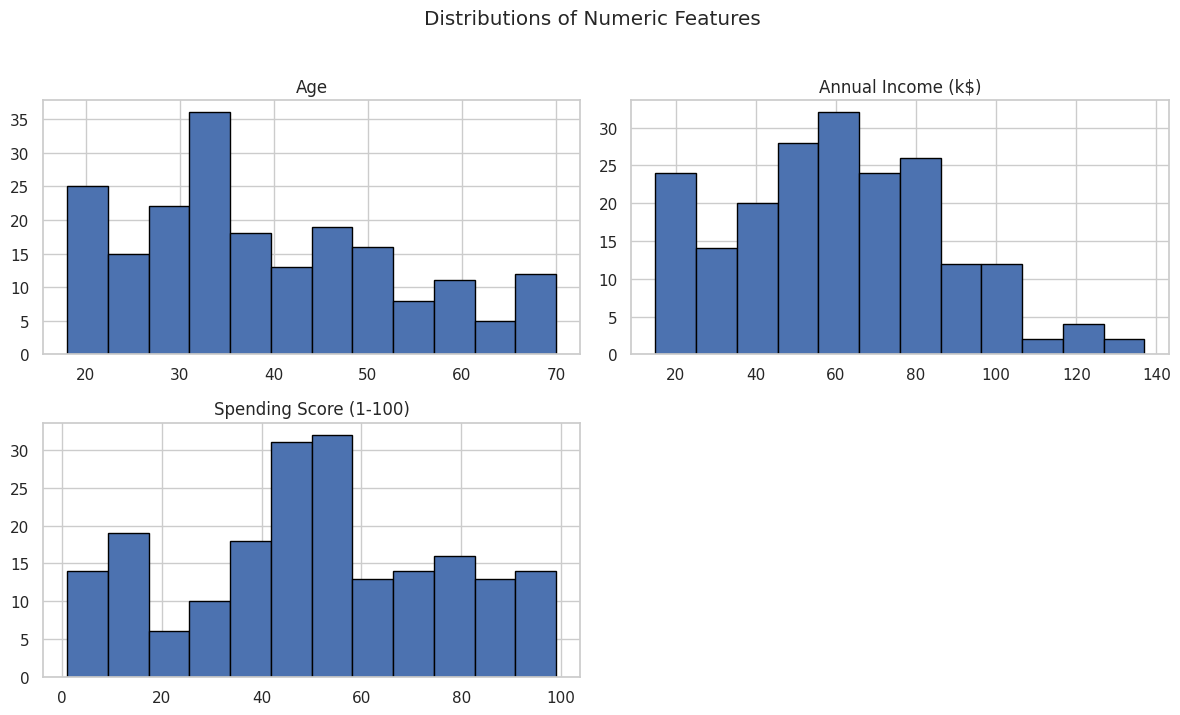

In [13]:
df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].hist(
    figsize=(12, 7), bins=12, edgecolor="black"
)
plt.suptitle("Distributions of Numeric Features", y=1.02)
plt.tight_layout()
plt.show()

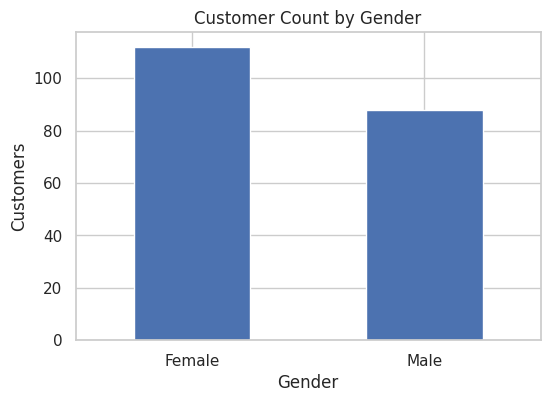

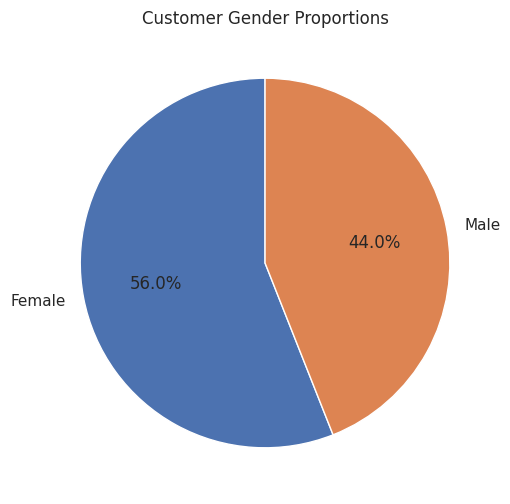

In [14]:
df["Gender"].value_counts().plot(kind="bar", figsize=(6, 4))
plt.title("Customer Count by Gender")
plt.xlabel("Gender"); plt.ylabel("Customers"); plt.xticks(rotation=0)
plt.show()

df["Gender"].value_counts().plot(kind="pie", autopct="%1.1f%%", figsize=(6, 6), startangle=90)
plt.title("Customer Gender Proportions"); plt.ylabel("")
plt.show()

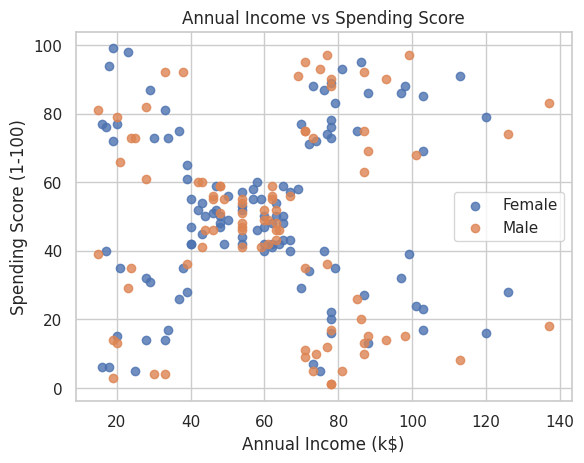

In [15]:
for gender, group in df.groupby("Gender"):
    plt.scatter(group[features[0]], group[features[1]], label=gender, alpha=0.8)
plt.title("Annual Income vs Spending Score")
plt.xlabel(features[0]); plt.ylabel(features[1]); plt.legend()
plt.show()

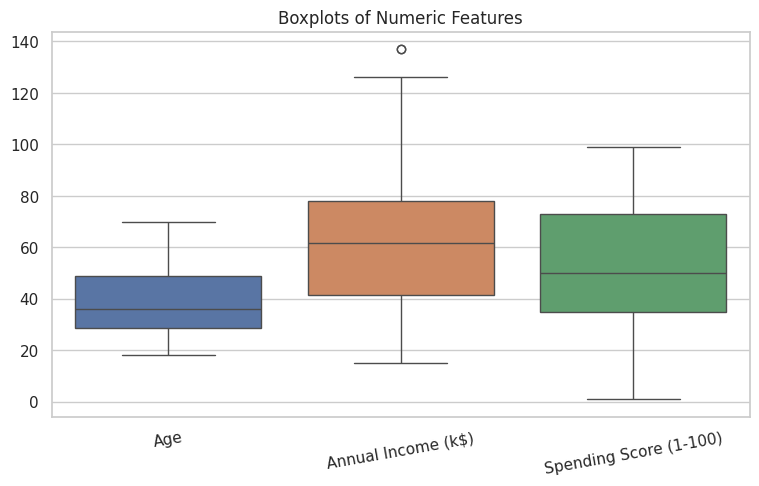

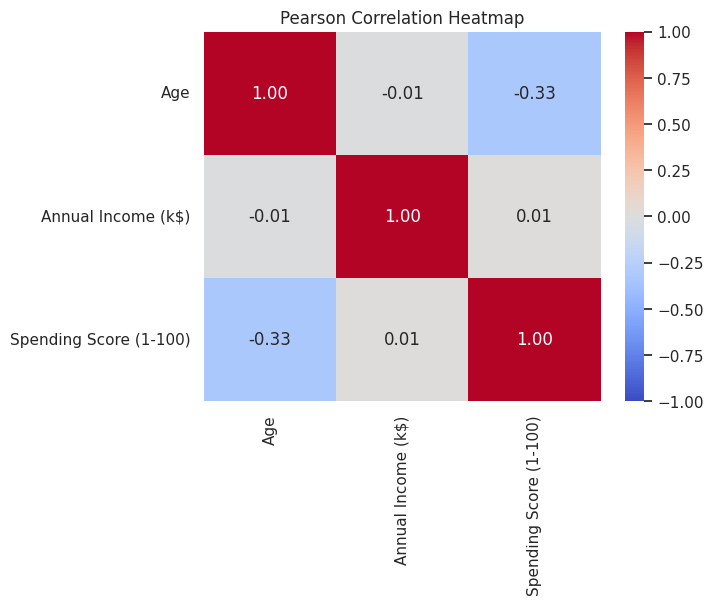

In [16]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]])
plt.title("Boxplots of Numeric Features")
plt.xticks(rotation=10); plt.show()

corr = df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Pearson Correlation Heatmap")
plt.show()

# D. Statistical Analysis

In [17]:
numeric_features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
rows = []
for col in numeric_features:
    s = df[col].dropna()
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    rows.append({
        "Feature": col,
        "Min": s.min(),
        "Max": s.max(),
        "Range": s.max() - s.min(),
        "IQR": iqr,
        "Mean Absolute Deviation": (s - s.mean()).abs().mean(),
        "Variance": s.var(),
        "Standard Deviation": s.std(),
        "IQR outlier count": int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())
    })
display(pd.DataFrame(rows).set_index("Feature").round(3))
print("Pearson correlation matrix:")
display(df[numeric_features].corr().round(3))

,Min,Max,Range,IQR,Mean Absolute Deviation,Variance,Standard Deviation,IQR outlier count
Feature,,,,,,,,
Age,18,70,52,20.25,11.660,195.133,13.969,0
Annual Income (k$),15,137,122,36.50,21.009,689.836,26.265,2
Spending Score (1-100),1,99,98,38.25,20.826,666.854,25.824,0


Pearson correlation matrix:


,Age,Annual Income (k$),Spending Score (1-100)
Age,1.000,-0.012,-0.327
Annual Income (k$),-0.012,1.000,0.010
Spending Score (1-100),-0.327,0.010,1.000


In [18]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled first five rows:\n", X_scaled[:5])

Scaled first five rows:
 [[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


# E. Model Training

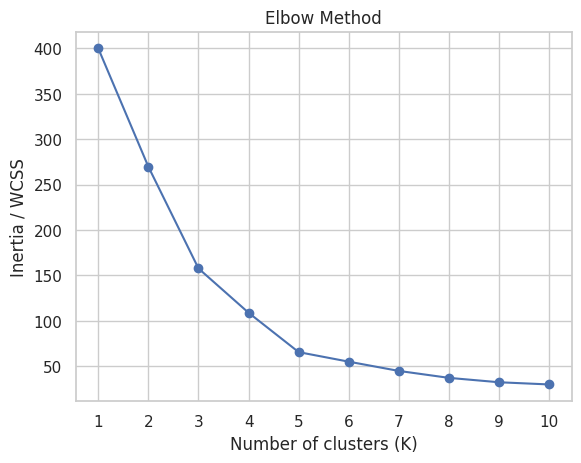

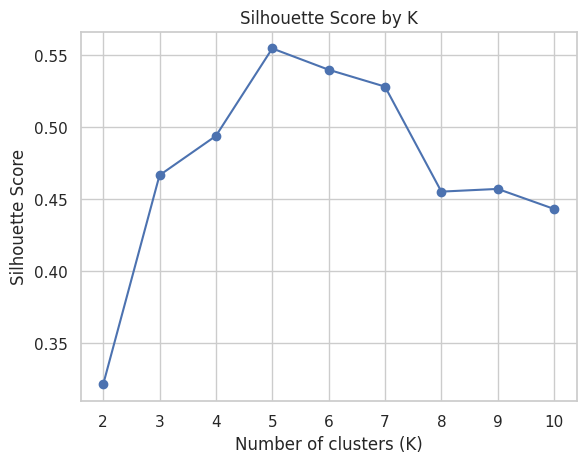

,K,Inertia,Silhouette Score
0,2,269.6910,0.3213
1,3,157.7040,0.4666
2,4,108.9213,0.4939
3,5,65.5684,0.5547
4,6,55.0573,0.5399
5,7,44.8648,0.5281
6,8,37.2282,0.4552
7,9,32.3923,0.4571
8,10,29.9819,0.4432


Highest silhouette score among tested K: 5


In [19]:
inertias = []
silhouette_scores = []
k_values = range(2, 11)

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    if k >= 2:
        silhouette_scores.append(silhouette_score(X_scaled, labels))

plt.plot(range(1, 11), inertias, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia / WCSS")
plt.xticks(range(1, 11))
plt.show()

plt.plot(list(k_values), silhouette_scores, marker="o")
plt.title("Silhouette Score by K")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.show()

score_table = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias[1:],
    "Silhouette Score": silhouette_scores
})
display(score_table.round(4))
print("Highest silhouette score among tested K:", int(score_table.loc[score_table["Silhouette Score"].idxmax(), "K"]))

In [20]:
chosen_k = 5

kmeans = KMeans(
    n_clusters=chosen_k,
    init="k-means++",
    n_init=20,
    max_iter=300,
    random_state=RANDOM_STATE
)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Chosen K:", chosen_k)
print("Inertia:", round(kmeans.inertia_, 4))
print("Silhouette Score:", round(silhouette_score(X_scaled, df["Cluster"]), 4))
print("Cluster sizes:")
display(df["Cluster"].value_counts().sort_index().to_frame("Customer count"))

Chosen K: 5
Inertia: 65.5684
Silhouette Score: 0.5547
Cluster sizes:


,Customer count
Cluster,
0,81
1,39
2,22
3,35
4,23


# F. Prediction and Evaluation

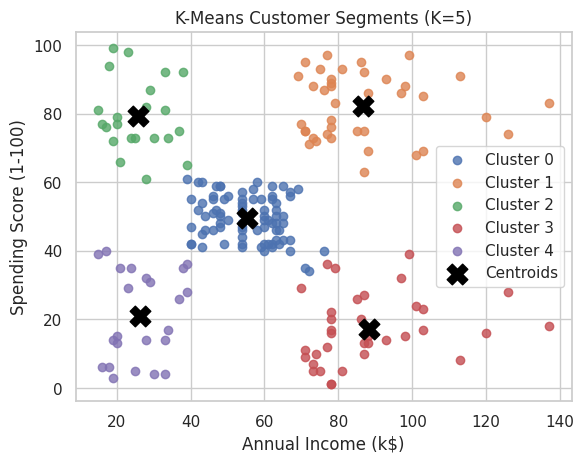

In [21]:
centers = scaler.inverse_transform(kmeans.cluster_centers_)

for cluster_id, group in df.groupby("Cluster"):
    plt.scatter(group[features[0]], group[features[1]], label=f"Cluster {cluster_id}", alpha=.8)
plt.scatter(centers[:, 0], centers[:, 1], marker="X", s=220, color="black", label="Centroids")
plt.title(f"K-Means Customer Segments (K={chosen_k})")
plt.xlabel(features[0]); plt.ylabel(features[1]); plt.legend()
plt.show()

,Customers,Mean_Age,Mean_Income,Mean_Spending
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


Gender percentages within each cluster:


Gender,Female,Male
Cluster,,
0,59.3,40.7
1,53.8,46.2
2,59.1,40.9
3,45.7,54.3
4,60.9,39.1


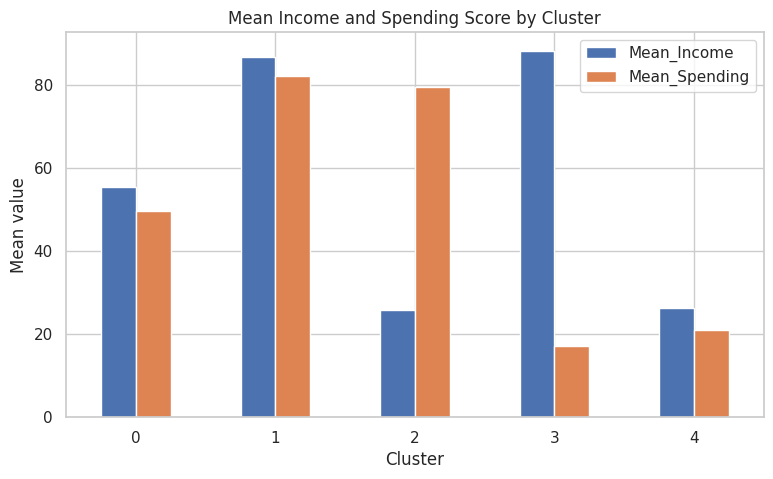

In [22]:
profile = df.groupby("Cluster").agg(
    Customers=("Cluster", "size"),
    Mean_Age=("Age", "mean"),
    Mean_Income=("Annual Income (k$)", "mean"),
    Mean_Spending=("Spending Score (1-100)", "mean")
).round(2)
display(profile)

if "Gender" in df.columns:
    print("Gender percentages within each cluster:")
    display(pd.crosstab(df["Cluster"], df["Gender"], normalize="index").mul(100).round(1))

profile[["Mean_Income", "Mean_Spending"]].plot(kind="bar", figsize=(9, 5))
plt.title("Mean Income and Spending Score by Cluster")
plt.xlabel("Cluster"); plt.ylabel("Mean value"); plt.xticks(rotation=0)
plt.show()

In [23]:
# Example only: annual income = $60,000 and spending score = 50
new_customer = pd.DataFrame({
    "Annual Income (k$)": [60],
    "Spending Score (1-100)": [50]
})
new_scaled = scaler.transform(new_customer)
predicted_cluster = kmeans.predict(new_scaled)[0]
print("Predicted cluster for the example customer:", predicted_cluster)

Predicted cluster for the example customer: 0


In [24]:
df.to_csv("mall_customers_with_clusters.csv", index=False)
print("Saved: mall_customers_with_clusters.csv")

Saved: mall_customers_with_clusters.csv


In [25]:
# Check values that may be inappropriate for this dataset
print("Gender categories:", sorted(df["Gender"].dropna().unique().tolist()))
print("Age outside 1–100:", ((df["Age"] < 1) | (df["Age"] > 100)).sum())
print("Annual income below 0:", (df["Annual Income (k$)"] < 0).sum())
print("Spending score outside 1–100:",
      ((df["Spending Score (1-100)"] < 1) | (df["Spending Score (1-100)"] > 100)).sum())

# Encoding is not performed because Gender is not part of the two-feature clustering model.
print("Model features (numeric):", features)
print("Categorical encoding required for selected model: No")

Gender categories: ['Female', 'Male']
Age outside 1–100: 0
Annual income below 0: 0
Spending score outside 1–100: 0
Model features (numeric): ['Annual Income (k$)', 'Spending Score (1-100)']
Categorical encoding required for selected model: No


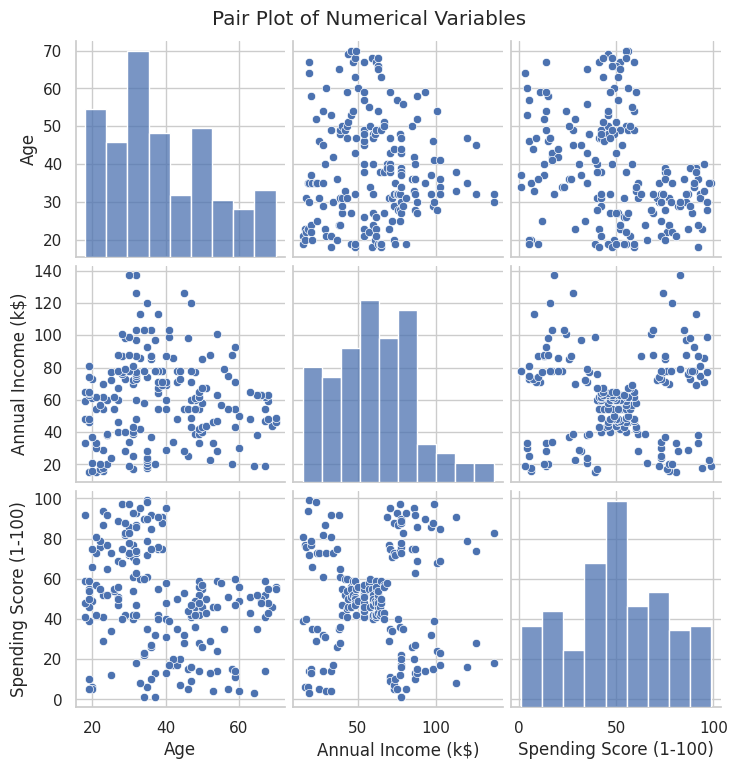

In [26]:
# Pair plot shows pairwise relationships among the three numeric descriptive variables.
# It is exploratory; the final K-Means model uses only income and spending score.
sns.pairplot(df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]])
plt.suptitle("Pair Plot of Numerical Variables", y=1.02)
plt.show()

In [27]:
from scipy.stats import zscore

numeric_features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
outlier_rows = []
for col in numeric_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    iqr_count = int(((df[col] < lower) | (df[col] > upper)).sum())
    z = np.abs(zscore(df[col], nan_policy="omit"))
    z_count = int((z > 3).sum())
    outlier_rows.append({
        "Feature": col, "IQR lower bound": lower, "IQR upper bound": upper,
        "IQR outlier count": iqr_count, "Z-score > 3 count": z_count
    })
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)

,Feature,IQR lower bound,IQR upper bound,IQR outlier count,Z-score > 3 count
0,Age,-1.625,79.375,0,0
1,Annual Income (k$),-13.250,132.750,2,0
2,Spending Score (1-100),-22.625,130.375,0,0


# G. Training/Evaluation Curves

,K,Inertia/WCSS,Silhouette Score
0,2,269.691012,0.321271
1,3,157.704008,0.466585
2,4,108.921317,0.493907
3,5,65.568408,0.554657
4,6,55.057348,0.539880
5,7,44.864756,0.528149
6,8,37.148117,0.456721
7,9,32.392268,0.457085
8,10,29.685788,0.436212


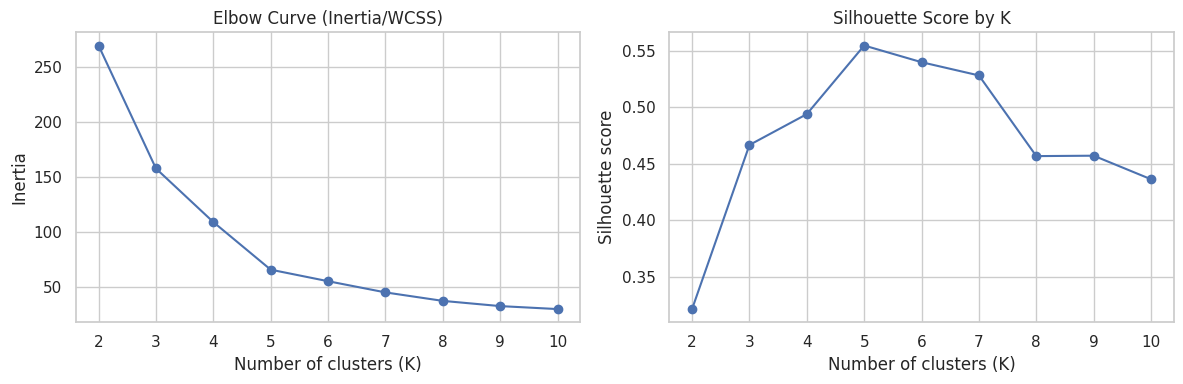

Highest tested silhouette score: K=5, score=0.555.
K=5 is selected for this project because it balances cluster quality and interpretable customer segments.


In [28]:
# Recalculate both metrics in a single table for reproducible reporting.
evaluation_rows = []
for k in range(2, 11):
    candidate = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = candidate.fit_predict(X_scaled)
    evaluation_rows.append({
        "K": k,
        "Inertia/WCSS": candidate.inertia_,
        "Silhouette Score": silhouette_score(X_scaled, labels)
    })
evaluation_df = pd.DataFrame(evaluation_rows)
display(evaluation_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(evaluation_df["K"], evaluation_df["Inertia/WCSS"], marker="o")
axes[0].set_title("Elbow Curve (Inertia/WCSS)")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")
axes[1].plot(evaluation_df["K"], evaluation_df["Silhouette Score"], marker="o")
axes[1].set_title("Silhouette Score by K")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

best_row = evaluation_df.loc[evaluation_df["Silhouette Score"].idxmax()]
print(f"Highest tested silhouette score: K={int(best_row['K'])}, "
      f"score={best_row['Silhouette Score']:.3f}.")
print("K=5 is selected for this project because it balances cluster quality and interpretable customer segments.")